# Practical Application III: Comparing Classifiers

## Which bank clients will say yes to a term deposit?

**UC Berkeley Machine Learning and Artificial Intelligence Professional Certificate**

**Overview.** This notebook compares four classifiers from this part of the program, **K-Nearest Neighbors, Logistic Regression, Decision Trees and Support Vector Machines**, on data from a Portuguese bank's telephone marketing campaigns. The aim is to find out which clients are worth calling to offer a term deposit, and to give the marketing team advice it can act on.

The notebook follows the eleven numbered problems of the assignment, then ends with a **Findings** section written for a non-technical audience and a **Next Steps** section.

**Contents**

1. Understanding the data
2. Reading in the data
3. Understanding the features (descriptive and inferential statistics)
4. Understanding the task (business objective)
5. Engineering features
6. Train/test split
7. A baseline model
8. A simple model
9. Scoring the model
10. Model comparisons
11. Improving the model (metric, features, grid search, interpretation, thresholds, costs)
12. Final model, findings and next steps

---
## Problem 1: Understanding the Data

> *Prompt: Read the UCI description and the Materials and Methods section of the paper. How many marketing campaigns does this data represent?*

The data come from Moro, Cortez and Rita (2014), *A Data-Driven Approach to Predict the Success of Bank Telemarketing*, and are published in the UCI Machine Learning Repository (Bank Marketing dataset).

**The data represent 17 marketing campaigns**, run by a Portuguese bank's own contact center between **May 2008 and November 2010**. The paper reports 79,354 contacts for the whole database. The file used here, `bank-additional-full.csv`, is the cleaned version with **41,188 contacts**, ordered by date, with five social and economic indicators added. Each row is one phone contact and the bank offered a long-term deposit with attractive interest rates.

Two points shape everything that follows:

- **The target is imbalanced.** Only a minority of contacts end in a subscription, so accuracy alone will be misleading.
- **The rows are in date order.** A random train/test split ignores time, so I add a time-based check at the end.

---
## Problem 2: Read in the Data

> *Prompt: Use pandas to read in `bank-additional-full.csv` and assign it to a meaningful variable name.*

In [1]:
## standard data handling and plotting libraries
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

## keep the output readable
warnings.filterwarnings("ignore")

## display and plotting defaults
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 150)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
BLUE, GOLD, GREY = "#003262", "#FDB515", "#9A9A9A"   # UC Berkeley palette
RANDOM_STATE = 10                                      # same seed throughout
os.makedirs("images", exist_ok=True)

def save_fig(name):
    """Save the current figure into images/ so the README can show it."""
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")

In [2]:
## scikit-learn imports, grouped by role
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay)

In [3]:
## the full dataset: one row per phone contact, semicolon separated
df = pd.read_csv("data/bank-additional-full.csv", sep=";")

## dots in column names are awkward in pandas, so replace them with underscores
df.columns = df.columns.str.replace(".", "_", regex=False)

print("rows, columns:", df.shape)
df.head()

rows, columns: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


---
## Problem 3: Understanding the Features

> *Prompt: Examine the data description, and determine if any of the features are missing values or need to be coerced to a different data type.*

The 20 predictors fall into four groups:

| Group | Columns |
|---|---|
| **Client** | `age`, `job`, `marital`, `education`, `default`, `housing`, `loan` |
| **Last contact of this campaign** | `contact`, `month`, `day_of_week`, `duration` |
| **Other** | `campaign` (contacts in this campaign), `pdays` (days since previous campaign, **999 = never contacted**), `previous`, `poutcome` |
| **Social and economic context** | `emp_var_rate`, `cons_price_idx`, `cons_conf_idx`, `euribor3m`, `nr_employed` |

The target `y` records whether the client subscribed a term deposit.

**Important warning from the data providers.** `duration` is the length of the call, which is only known *after* the call ends, and the outcome is known right after that. A model that uses it looks excellent but cannot be used to decide *whom to call*. I keep it out of the realistic models and use it only as a clearly labelled benchmark in Problem 11.

### 3.1 Data types, missing values and duplicates

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp_var_rate    41188 non-null  float64
 16  cons_price_idx  41188 non-null  float64
 17  cons_conf_idx   41188 non-null  float64
 1

In [5]:
## missing values (None expected) and exact duplicate rows
print("missing values:", int(df.isna().sum().sum()))
print("exact duplicate rows:", int(df.duplicated().sum()))

## the data providers code missing categorical values as the string "unknown"
categorical_cols = df.select_dtypes(include="object").columns.drop("y")
unknown_pct = (df[categorical_cols] == "unknown").mean().mul(100).sort_values(ascending=False)
unknown_pct[unknown_pct > 0].round(1).to_frame("% 'unknown'")

missing values: 0
exact duplicate rows: 12


,% 'unknown'
default,20.9
education,4.2
housing,2.4
loan,2.4
job,0.8
marital,0.2


**What I found.**

- **No true missing values.** All 21 columns are complete. The providers instead code missing categorical answers as the string `"unknown"`. This is most common for `default` (20.9% unknown), then `education` (4.2%), `housing` and `loan` (2.4% each), `job` (0.8%) and `marital` (0.2%).
- **I keep `"unknown"` as its own category** rather than dropping rows or guessing a value. Dropping would lose over 20% of the rows because of `default`, and "unknown" may carry information of its own (a client who does not disclose a credit default behaves differently, as the subscription rates in 3.4 show).
- **12 exact duplicate rows (0.03%).** The categorical columns are coarse, so two different clients can produce the same record. They are too few to matter, so I leave them in.
- **Data types need little coercion.** Numeric columns are already numeric and categorical columns are text. `month` and `day_of_week` stay categorical. Two columns need care: the **target `y`** (yes/no) is converted to 0/1, and **`pdays` uses 999 as a placeholder for "never contacted before"**, which is not a real number of days. I handle that in Problem 5.

### 3.2 Summary statistics

In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp_var_rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons_price_idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons_conf_idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr_employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


- **`age`** runs from 17 to 98, with a median of 38.
- **`campaign`** (contacts in this campaign) has a median of 2 but a maximum of 56. Only 2.1% of clients were contacted more than 10 times.
- **`pdays`** is 999 for 96.3% of contacts, so almost all clients had never been contacted in a previous campaign. Just 13.7% have `previous` above 0.
- **`duration`** (call length) ranges from 0 to 4,918 seconds, with a median of 180 seconds. Subscribers' calls are much longer (median 449 s versus 164 s), which is exactly why it cannot be used to decide whom to call.
- The **economic indicators** take only a few distinct values over time (they are quarterly or monthly numbers), so they behave more like a label for the time period than a measure of the client.

### 3.3 The target: how many clients subscribe?

no: 36,548   yes: 4,640   subscription rate: 11.3%


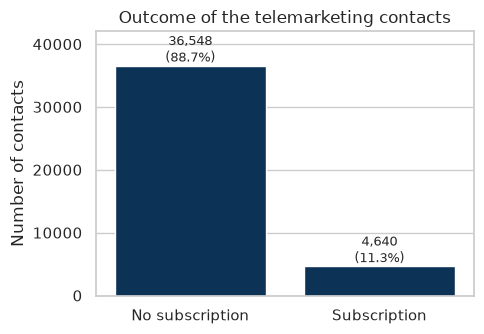

In [7]:
## create a 0/1 version of the target for plotting and modeling
df["subscribed"] = (df["y"] == "yes").astype(int)
base_rate = df["subscribed"].mean()

counts = df["y"].value_counts()
print(f"no: {counts['no']:,}   yes: {counts['yes']:,}   subscription rate: {base_rate:.1%}")

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=["No subscription", "Subscription"], y=[counts["no"], counts["yes"]],
            color=BLUE, ax=ax)
for patch, n in zip(ax.patches, [counts["no"], counts["yes"]]):
    ax.annotate(f"{n:,}\n({n / len(df):.1%})", (patch.get_x() + patch.get_width() / 2, n),
                ha="center", va="bottom", fontsize=9)
ax.set_title("Outcome of the telemarketing contacts")
ax.set_ylabel("Number of contacts")
ax.set_ylim(0, counts["no"] * 1.15)
plt.tight_layout(); plt.show()

Only **11.3%** of the 41,188 contacts ended in a subscription (95% confidence interval 11.0% to 11.6%, computed in 3.6). The classes are strongly imbalanced, so a model that always says "no" is 88.7% accurate. Accuracy cannot be the headline measure.

### 3.4 Who subscribes? Subscription rate by category

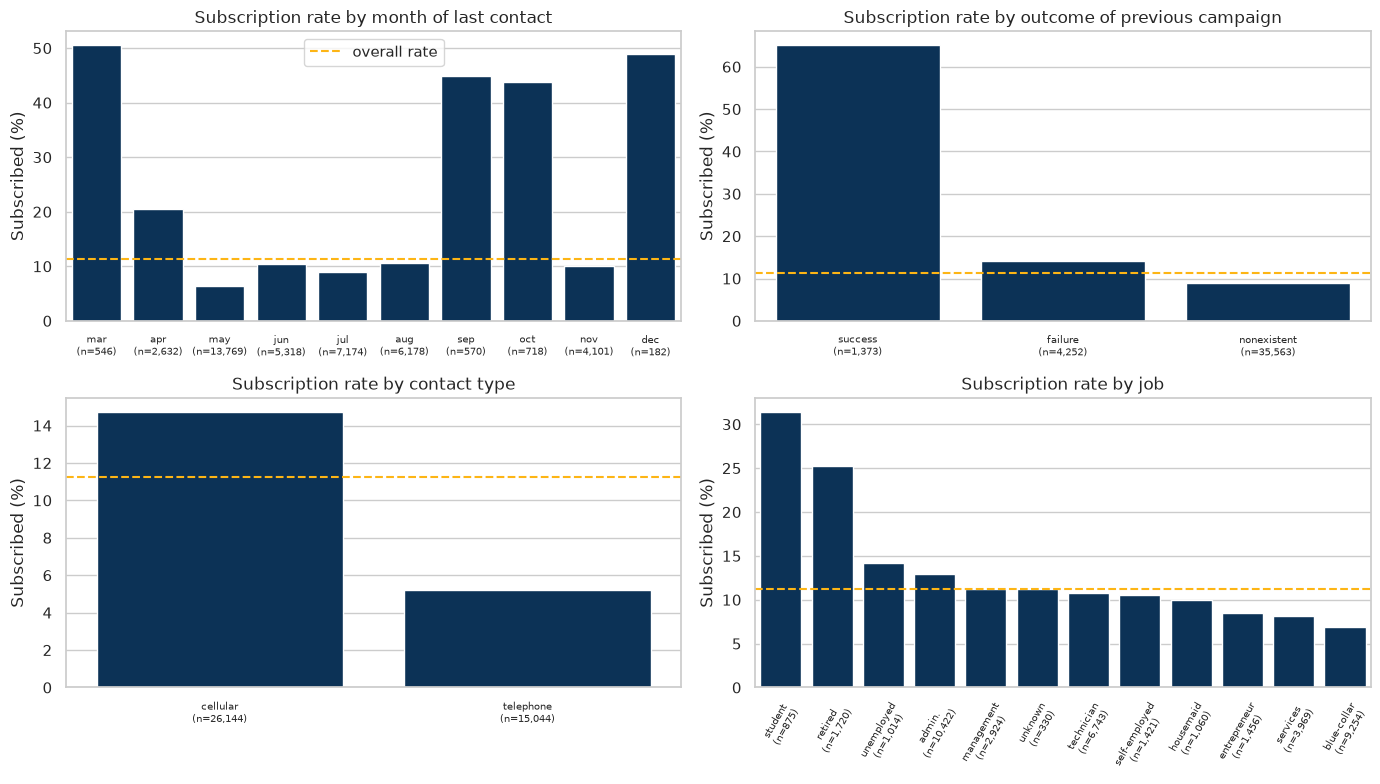

In [8]:
## subscription rate for a categorical column, with the number of contacts behind each bar
def plot_rate(ax, col, order=None, title=None):
    stats_ = df.groupby(col)["subscribed"].agg(rate="mean", n="size")
    stats_ = stats_.reindex(order) if order else stats_.sort_values("rate", ascending=False)
    labels = [f"{idx}\n(n={int(n):,})" for idx, n in zip(stats_.index, stats_["n"])]
    sns.barplot(x=labels, y=stats_["rate"] * 100, color=BLUE, ax=ax)
    ax.axhline(base_rate * 100, color=GOLD, linestyle="--", linewidth=1.5, label="overall rate")
    ax.set_title(title or f"Subscription rate by {col}")
    ax.set_xlabel(""); ax.set_ylabel("Subscribed (%)")
    ax.tick_params(axis="x", labelsize=7)

month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
plot_rate(axes[0, 0], "month", month_order, "Subscription rate by month of last contact")
plot_rate(axes[0, 1], "poutcome", None, "Subscription rate by outcome of previous campaign")
plot_rate(axes[1, 0], "contact", None, "Subscription rate by contact type")
plot_rate(axes[1, 1], "job", None, "Subscription rate by job")
axes[1, 1].tick_params(axis="x", rotation=60)
axes[0, 0].legend()
plt.tight_layout(); save_fig("eda_subscription_rates"); plt.show()

**What the charts show** (each bar is labelled with the number of contacts behind it; the gold dashed line is the overall 11.3% rate):

- **Outcome of the previous campaign** is the strongest signal. Clients who said yes last time subscribed **65.1%** of the time (1,373 clients), versus 14.2% after a previous failure and 8.8% for clients with no previous contact.
- **Month.** March (50.5%), September (44.9%), October (43.9%) and December (48.9%) have very high rates, but each has fewer than 720 contacts. **May has the lowest rate (6.4%) and a third of all contacts (13,769)**, so the bank put most of its calling effort into its weakest month.
- **Contact type.** Cellular contacts subscribe at 14.7% versus 5.2% for landlines.
- **Job.** Students (31.4%) and retired clients (25.2%) subscribe most. Blue-collar workers (6.9%) and services staff (8.1%) subscribe least.
- **Age** has a U shape: about 24% for clients under 25, about 9% for ages 35 to 54, and 47% for clients over 64 (a small group).

These are associations in the data, not proof of cause. For example, the months with high rates are also months with very different economic conditions and very few calls.

### 3.5 Who subscribes? Numeric features

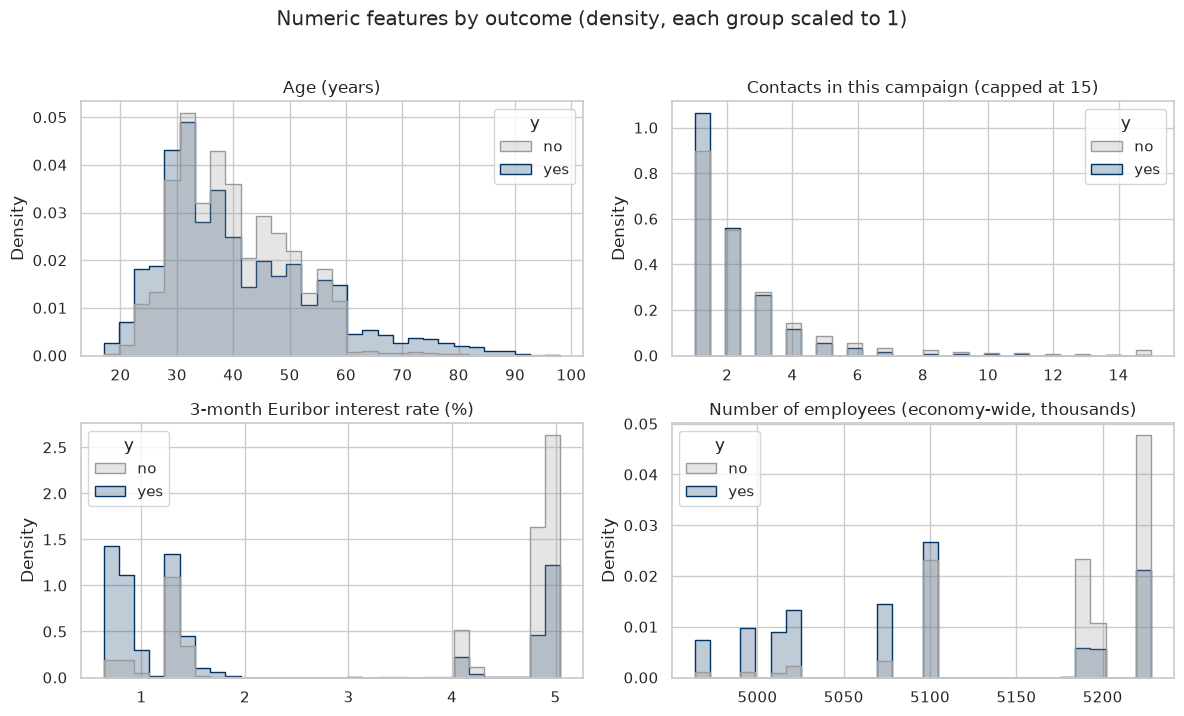

In [9]:
## compare the distributions of four numeric features for subscribers and non-subscribers
plot_df = df.assign(campaign=df["campaign"].clip(upper=15))   # a few clients were called 40+ times

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (col, title) in zip(axes.ravel(), [
        ("age", "Age (years)"),
        ("campaign", "Contacts in this campaign (capped at 15)"),
        ("euribor3m", "3-month Euribor interest rate (%)"),
        ("nr_employed", "Number of employees (economy-wide, thousands)")]):
    sns.histplot(data=plot_df, x=col, hue="y", stat="density", common_norm=False,
                 element="step", palette={"no": GREY, "yes": BLUE}, bins=30, ax=ax)
    ax.set_title(title); ax.set_xlabel("")
plt.suptitle("Numeric features by outcome (density, each group scaled to 1)", y=1.02)
plt.tight_layout(); plt.show()

Subscribers (blue) and non-subscribers (grey) differ sharply on the **economic indicators**: subscribers are concentrated at low interest rates (`euribor3m`, median 1.27% versus 4.86%) and lower economy-wide employment (`nr_employed`). Age and the number of contacts show much smaller differences (the tests in 3.6 quantify this).

One caution: the economic indicators have few distinct values because they are published quarterly or monthly. They largely tell us **when** a call happened, not anything about the client. That matters again in Problem 11.8.

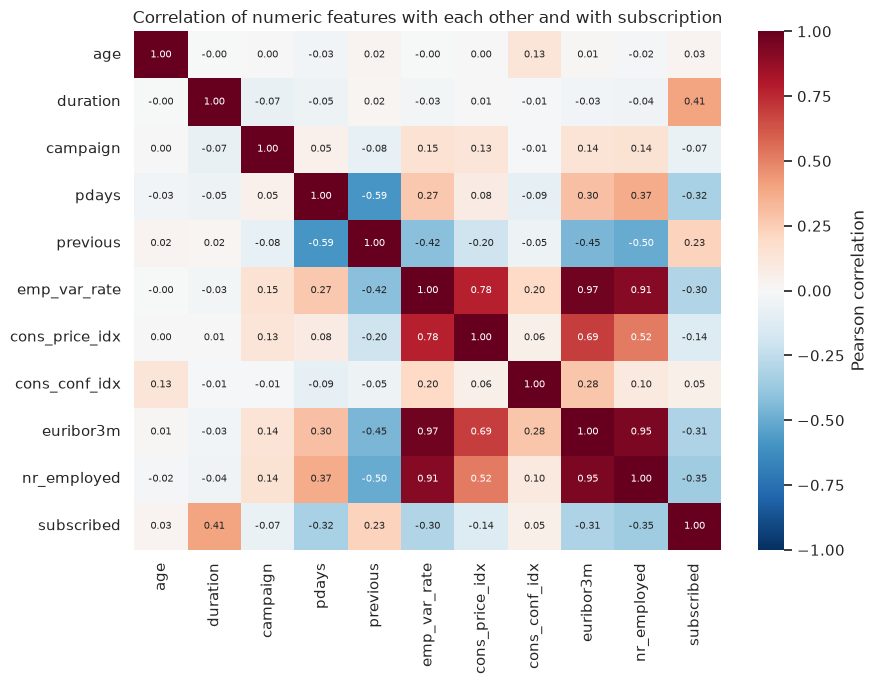

In [10]:
## correlation among the numeric columns and the target
numeric_cols = df.select_dtypes(include=np.number).columns.drop("subscribed").tolist()
corr = df[numeric_cols + ["subscribed"]].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7}, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation of numeric features with each other and with subscription")
plt.tight_layout(); plt.show()

- The three economic indicators are **almost the same signal**: `emp_var_rate` and `euribor3m` correlate at 0.97, `euribor3m` and `nr_employed` at 0.95, and `emp_var_rate` and `nr_employed` at 0.91. Putting all of them in a linear model makes individual coefficients unstable, because the model can swap weight between them. I use regularization and avoid reading single economic coefficients too literally.
- With the target, the strongest correlations are with `nr_employed` (-0.35), `euribor3m` (-0.31), `emp_var_rate` (-0.30), `pdays` (-0.32) and `previous` (+0.23).
- `age` has almost no linear correlation with subscription (0.03), but the chart in 3.4 shows a U-shaped relationship that a straight-line correlation misses.

### 3.6 Inferential statistics: are these differences real or noise?

The charts show differences in subscription rates. With over 40,000 rows even tiny differences can be statistically significant, so I report an **effect size** next to every p-value.

- **Categorical features vs outcome:** chi-square test of independence, with **Cramér's V** (0 = no association, 1 = perfect) as the effect size.
- **Numeric features vs outcome:** Mann-Whitney U test (the numeric features are skewed, so I avoid assuming normality), with the **rank-biserial correlation** as the effect size (0 = no difference, ±1 = complete separation).
- **Multiple testing:** about 20 tests are run, so I judge significance against a Bonferroni-adjusted threshold of 0.05 / 20 = 0.0025.

In [11]:
## overall subscription rate with a 95% Wilson confidence interval
def wilson_ci(successes, n, z=1.96):
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

low, high = wilson_ci(df["subscribed"].sum(), len(df))
print(f"overall subscription rate: {base_rate:.2%}  (95% CI {low:.2%} to {high:.2%})")

## chi-square tests for each categorical feature
cat_rows = []
for col in categorical_cols:
    table = pd.crosstab(df[col], df["y"])
    chi2, p_value, dof, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    cat_rows.append({"feature": col, "chi2": chi2, "p-value": p_value, "Cramer's V": cramers_v})
chi_results = pd.DataFrame(cat_rows).sort_values("Cramer's V", ascending=False).set_index("feature")
chi_results.round(4).assign(**{"p-value": chi_results["p-value"].map("{:.1e}".format)})

overall subscription rate: 11.27%  (95% CI 10.96% to 11.57%)


,chi2,p-value,Cramer's V
feature,,,
poutcome,4230.5238,0.0e+00,0.3205
month,3101.1494,0.0e+00,0.2744
job,961.2424,4.2e-199,0.1528
contact,862.3184,1.5e-189,0.1447
default,406.5775,5.2e-89,0.0994
education,193.1059,3.3e-38,0.0685
marital,122.6552,2.1e-26,0.0546
day_of_week,26.1449,3.0e-05,0.0252
housing,5.6845,5.8e-02,0.0117


In [12]:
## Mann-Whitney U tests for each numeric feature (subscribers vs non-subscribers)
num_rows = []
yes, no = df[df["subscribed"] == 1], df[df["subscribed"] == 0]
for col in numeric_cols:
    u_stat, p_value = stats.mannwhitneyu(yes[col], no[col], alternative="two-sided")
    rank_biserial = 2 * u_stat / (len(yes) * len(no)) - 1     # >0: subscribers tend to be higher
    num_rows.append({"feature": col, "median (yes)": yes[col].median(), "median (no)": no[col].median(),
                     "p-value": p_value, "rank-biserial r": rank_biserial})
mw_results = pd.DataFrame(num_rows).set_index("feature").reindex(
    pd.Series([r["rank-biserial r"] for r in num_rows], index=[r["feature"] for r in num_rows]).abs().sort_values(ascending=False).index)
mw_results.round(3).assign(**{"p-value": mw_results["p-value"].map("{:.1e}".format)})

,median (yes),median (no),p-value,rank-biserial r
duration,449.000,163.500,0.0e+00,0.637
nr_employed,5099.100,5195.800,0.0e+00,-0.498
euribor3m,1.266,4.857,0.0e+00,-0.487
emp_var_rate,-1.800,1.100,0.0e+00,-0.434
cons_price_idx,93.200,93.918,9.6e-136,-0.221
previous,0.000,0.000,0.0e+00,0.219
pdays,999.000,999.000,0.0e+00,-0.193
campaign,2.000,2.000,3.4e-38,-0.110
cons_conf_idx,-40.400,-41.800,5.9e-17,0.075
age,37.000,38.000,1.6e-02,-0.022


**Interpretation of the statistical tests**

- **Overall rate.** The subscription rate is 11.27%, with a narrow 95% confidence interval (10.96% to 11.57%), so the base rate is precisely estimated.
- **Categorical features.** The association with subscription is strongest for **`poutcome`** (Cramér's V = 0.32), then **`month`** (0.27), **`job`** (0.15) and **`contact`** (0.14). These are small to moderate effect sizes. `default` (0.10), `education` (0.07) and `marital` (0.05) are statistically significant but weak. **`housing` (p = 0.058) and `loan` (p = 0.58) are not significant**, even with 41,000 rows, so whether a client has a home or personal loan tells us essentially nothing about subscription. `day_of_week` is significant (p = 3e-5) but tiny (V = 0.025).
- **Numeric features.** The biggest differences are in `duration` (r = 0.64, call length, a leaky feature), `nr_employed` (-0.50), `euribor3m` (-0.49) and `emp_var_rate` (-0.43). In plain terms, subscribers come from periods of lower interest rates and lower employment indicators. `previous` (+0.22) and `pdays` (-0.19) show that prior contact helps. `age` is not significant after the multiple-testing adjustment (p = 0.016 against 0.0025).
- **Statistical versus practical significance.** With this many rows, p-values are tiny for almost everything (many print as 0.0e+00), so effect sizes are more useful than p-values. None of the individual client features has a large effect size, which warns us that predicting individual clients will be hard. That is what the models show.

---
## Problem 4: Understanding the Task

> *Prompt: After examining the description and data, clearly state the Business Objective of the task.*

### Business objective

The bank sells a **term deposit** by telephone. Every call costs agent time, and many clients who are called decline (and some are annoyed by repeated calls). The business objective is to **raise the number of subscriptions the bank wins per call made** by spending calls on clients who are most likely to say yes, and by stopping calls to those who are not.

### Machine learning objective

Build a **binary classifier** that, *before the call is made*, scores each client on how likely they are to subscribe, so that the call list can be ranked and trimmed. A useful model must:

1. beat the "nobody subscribes" baseline by a margin that justifies using it,
2. **rank clients well**, so the team can choose how deep into the list to call,
3. make the trade-off between wasted calls and missed subscribers explicit.

### Why accuracy is the wrong headline metric

Roughly nine in ten contacts say no, so a model that predicts "no" for everyone is about 89% accurate and finds no customers. I therefore report accuracy for comparison with the assignment, but **I select models on F1 for the "yes" class** and judge ranking quality with ROC AUC and precision-recall AUC.

$$
\text{precision} = \frac{TP}{TP + FP}, \qquad
\text{recall} = \frac{TP}{TP + FN}, \qquad
F_1 = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}
$$

- **Precision**: of the clients the model says will subscribe, how many do? (the cost of wasted calls)
- **Recall**: of all the clients who would subscribe, how many does the model find? (the cost of missed sales)
- **F1** balances the two, and it ignores the large number of correctly predicted "no" clients that inflates accuracy.

---
## Problem 5: Engineering Features

> *Prompt: Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.*

The assignment starts with only the **seven client features** (`age`, `job`, `marital`, `education`, `default`, `housing`, `loan`). I use this "client-only" set for Problems 5 to 10, and widen the feature set in Problem 11.

**Encoding.** Six of the seven are categorical, so they are one-hot encoded with `drop="first"` to avoid perfect collinearity in the linear model. `handle_unknown="ignore"` stops a category that appears only in the test set from crashing the transform. The `"unknown"` label is kept as its own category, because not disclosing a loan or education may itself carry information.

**Scaling.** K-nearest neighbors and the RBF support vector machine both depend on distances, so numeric features are standardized.

**Leakage.** The scaler and encoder learn from data. Every transformer is therefore placed inside a `Pipeline`, so it is fit only on training data (and only on training folds during cross-validation).

In [13]:
## target: 1 if the client subscribed, 0 otherwise
y = df["subscribed"]
X = df.drop(columns=["y", "subscribed"])

## extra engineered columns used from Problem 11 onward
X["previously_contacted"] = (X["pdays"] != 999).astype(int)           # 999 means "never contacted"
X["days_since_prev_contact"] = X["pdays"].where(X["pdays"] != 999, 0) # real day counts only

## the feature sets: (numeric, categorical, passthrough)
client_cat = ["job", "marital", "education", "default", "housing", "loan"]
contact_cat = ["contact", "month", "day_of_week", "poutcome"]
campaign_num = ["age", "campaign", "previous", "days_since_prev_contact"]
economic_num = ["emp_var_rate", "cons_price_idx", "cons_conf_idx", "euribor3m", "nr_employed"]

FEATURE_SETS = {
    "client only": (["age"], client_cat, []),
    ## adds contact and campaign history, but NOT the economy-wide indicators
    "no economic indicators": (campaign_num, client_cat + contact_cat, ["previously_contacted"]),
    ## adds the economic indicators as well
    "extended": (campaign_num + economic_num, client_cat + contact_cat, ["previously_contacted"]),
}
## benchmark only: the extended set plus call duration, which is NOT known before a call
FEATURE_SETS["extended + duration (benchmark)"] = (
    FEATURE_SETS["extended"][0] + ["duration"], FEATURE_SETS["extended"][1], FEATURE_SETS["extended"][2])

for name, (num, cat, pas) in FEATURE_SETS.items():
    print(f"{name:34s} numeric: {len(num):2d}  categorical: {len(cat):2d}  passthrough: {len(pas)}")

client only                        numeric:  1  categorical:  6  passthrough: 0
no economic indicators             numeric:  4  categorical: 10  passthrough: 1
extended                           numeric:  9  categorical: 10  passthrough: 1
extended + duration (benchmark)    numeric: 10  categorical: 10  passthrough: 1


In [14]:
## a reusable preprocessor: scale the numbers, one-hot encode the categories
def make_preprocessor(feature_set):
    numeric, categorical, passthrough = FEATURE_SETS[feature_set]
    steps = [("num", StandardScaler(), numeric),
             ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), categorical)]
    if passthrough:
        steps.append(("pass", "passthrough", passthrough))
    return ColumnTransformer(steps)

## a full pipeline = preprocessor + estimator, so nothing is ever fit outside training data
def make_pipeline(estimator, feature_set="client only"):
    return Pipeline([("prep", make_preprocessor(feature_set)), ("model", estimator)])

---
## Problem 6: Train/Test Split

> *Prompt: With your data prepared, split it into a train and test set.*

I use `test_size=0.33` and `random_state=10`, the convention used throughout the program, with a **stratified** split so that both halves keep the same share of subscribers (about 11%).

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=RANDOM_STATE, stratify=y)

print(f"train: {X_train.shape[0]:,} rows, subscription rate {y_train.mean():.2%}")
print(f"test:  {X_test.shape[0]:,} rows, subscription rate {y_test.mean():.2%}")

train: 27,595 rows, subscription rate 11.27%
test:  13,593 rows, subscription rate 11.26%


---
## Problem 7: A Baseline Model

> *Prompt: What is the baseline performance that our classifier should aim to beat?*

In [16]:
## baseline: always predict the majority class ("no")
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
baseline_train_acc = dummy.score(X_train, y_train)
baseline_test_acc = dummy.score(X_test, y_test)

baseline_pred = dummy.predict(X_test)
print(f"baseline train accuracy: {baseline_train_acc:.4f}")
print(f"baseline test accuracy:  {baseline_test_acc:.4f}")
print(f"baseline recall for subscribers: {recall_score(y_test, baseline_pred):.4f}")

baseline train accuracy: 0.8873
baseline test accuracy:  0.8874
baseline recall for subscribers: 0.0000


**The baseline to beat is 88.7% accuracy**, obtained by predicting "no subscription" for everyone. It finds **zero** subscribers (recall 0.000). Any useful model must find subscribers while keeping accuracy close to this level, so accuracy alone cannot show a model is good.

---
## Problem 8: A Simple Model

> *Prompt: Use Logistic Regression to build a basic model on your data.*

Logistic regression is the natural first model: it is fast, it produces probabilities, and its coefficients can be interpreted. It models the log-odds of subscribing as a linear function of the features.

In [17]:
## logistic regression at default settings on the client-only features
logreg_simple = make_pipeline(LogisticRegression(max_iter=1000), "client only")
logreg_simple.fit(X_train, y_train)
print("fitted; encoded feature count:", logreg_simple.named_steps["prep"].transform(X_train).shape[1])

fitted; encoded feature count: 28


---
## Problem 9: Score the Model

> *Prompt: What is the accuracy of your model?*

In [18]:
simple_train_acc = logreg_simple.score(X_train, y_train)
simple_test_acc = logreg_simple.score(X_test, y_test)
simple_pred = logreg_simple.predict(X_test)
simple_proba = logreg_simple.predict_proba(X_test)[:, 1]

print(f"train accuracy: {simple_train_acc:.4f}")
print(f"test accuracy:  {simple_test_acc:.4f}   (baseline {baseline_test_acc:.4f})")
print(f"test recall for subscribers: {recall_score(y_test, simple_pred):.4f}")
print(f"test ROC AUC: {roc_auc_score(y_test, simple_proba):.4f}")

train accuracy: 0.8873
test accuracy:  0.8874   (baseline 0.8874)
test recall for subscribers: 0.0000
test ROC AUC: 0.6495


**Test accuracy is 88.74%, exactly the same as the baseline**, and recall for subscribers is 0. With only the seven client features, the logistic regression predicts "no" for every client. It does carry some ranking information (ROC AUC 0.65, against 0.50 for a coin flip), but at the default 0.5 cutoff no client's predicted probability ever reaches 50%, because the base rate is only 11%. This is the clearest demonstration that accuracy is misleading here, and it shows that client demographics alone are weak predictors.

---
## Problem 10: Model Comparisons

> *Prompt: Compare Logistic Regression with KNN, Decision Tree and SVM using default settings. Fit and score each, and compare the fit times in a DataFrame.*

All four models use their default settings and the same client-only features. The four represent different ways of learning: a linear boundary, local voting among neighbors, axis-aligned rules, and a kernelized margin.

In [19]:
## the four default models
default_models = {
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "SVM (RBF kernel)": SVC(random_state=RANDOM_STATE),
}

## fit each one, recording the fit time, train accuracy and test accuracy
rows = [{"Model": "Baseline (majority class)", "Train Time (s)": 0.0,
         "Train Accuracy": baseline_train_acc, "Test Accuracy": baseline_test_acc}]
default_fitted = {}
for name, estimator in default_models.items():
    pipe = make_pipeline(estimator, "client only")
    start = time.time()
    pipe.fit(X_train, y_train)
    elapsed = time.time() - start
    default_fitted[name] = pipe
    rows.append({"Model": name, "Train Time (s)": elapsed,
                 "Train Accuracy": pipe.score(X_train, y_train),
                 "Test Accuracy": pipe.score(X_test, y_test)})

default_comparison = pd.DataFrame(rows).round(4)
default_comparison

,Model,Train Time (s),Train Accuracy,Test Accuracy
0,Baseline (majority class),0.0000,0.8873,0.8874
1,K-Nearest Neighbors,0.0265,0.8919,0.8775
2,Logistic Regression,0.0396,0.8873,0.8874
3,Decision Tree,0.2009,0.9196,0.8617
4,SVM (RBF kernel),16.9665,0.8883,0.8871


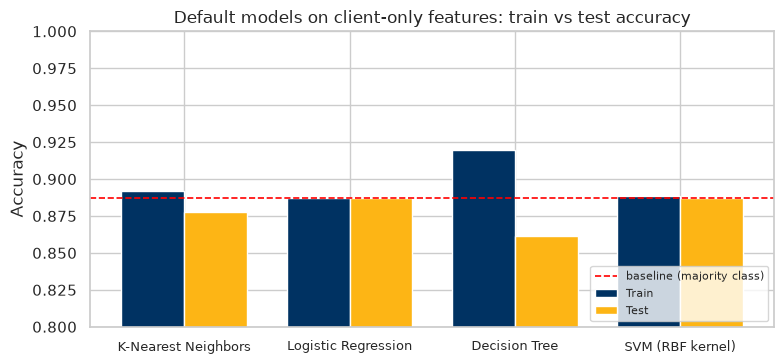

In [20]:
## train versus test accuracy: a large gap signals overfitting
plot_df = default_comparison[default_comparison["Model"] != "Baseline (majority class)"]
x = np.arange(len(plot_df)); width = 0.38

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(x - width / 2, plot_df["Train Accuracy"], width, color=BLUE, label="Train")
ax.bar(x + width / 2, plot_df["Test Accuracy"], width, color=GOLD, label="Test")
ax.axhline(baseline_test_acc, color="red", linestyle="--", linewidth=1.2, label="baseline (majority class)")
ax.set_xticks(x); ax.set_xticklabels(plot_df["Model"], fontsize=9)
ax.set_ylim(0.8, 1.0); ax.set_ylabel("Accuracy")
ax.set_title("Default models on client-only features: train vs test accuracy")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**Observations**

- **Nothing beats the baseline on accuracy.** Logistic regression (88.74%) and the SVM (88.71%) match it. KNN (87.75%) and the decision tree (86.17%) are *below* it.
- **The decision tree overfits.** Train accuracy is 91.96% but test accuracy is 86.17%, the widest gap of the four. An unconstrained tree grows until it memorizes the training data.
- **Fit time differs enormously.** Logistic regression, KNN and the tree fit in under a quarter of a second. The SVM takes about **18 seconds**, around 500 times longer than logistic regression, for no accuracy benefit.

In [21]:
## the same four models on metrics that respect the class imbalance
def score_model(model, X_eval, y_eval):
    pred = model.predict(X_eval)
    score = model.predict_proba(X_eval)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_eval)
    return {"Accuracy": accuracy_score(y_eval, pred),
            "Precision": precision_score(y_eval, pred, zero_division=0),
            "Recall": recall_score(y_eval, pred),
            "F1": f1_score(y_eval, pred),
            "ROC AUC": roc_auc_score(y_eval, score),
            "PR AUC": average_precision_score(y_eval, score)}

default_metrics = pd.DataFrame({name: score_model(m, X_test, y_test)
                                for name, m in default_fitted.items()}).T.round(4)
default_metrics

,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
K-Nearest Neighbors,0.8775,0.2994,0.0653,0.1072,0.5783,0.1480
Logistic Regression,0.8874,0.0000,0.0000,0.0000,0.6495,0.1898
Decision Tree,0.8617,0.2320,0.0986,0.1384,0.5697,0.1452
SVM (RBF kernel),0.8871,0.4000,0.0052,0.0103,0.5632,0.1713


Looking beyond accuracy changes the picture:

- **Logistic regression and the SVM find almost no subscribers.** Logistic regression has recall 0.000 and the SVM 0.005 (F1 of 0.000 and 0.010).
- **The tree and KNN find a few more** (recall 0.099 and 0.065) but with low precision (0.23 and 0.30), giving F1 of only 0.138 and 0.107.
- **Logistic regression ranks best.** Its ROC AUC (0.650) and PR AUC (0.190) are the highest of the four, even though its default predictions are useless. This suggests that the 0.5 cutoff and the features are the problem, not the algorithm. Problem 11 addresses both.

---
## Problem 11: Improving the Model

> *Prompt: Try to improve the models: tune hyperparameters with grid search, and adjust the performance metric.*

I take the improvements in this order:

1. **11.1** Choose and justify the evaluation metric.
2. **11.2** Revisit the features: add the contact, campaign and economic features, and show why `duration` must stay out.
3. **11.3** Tune every model with cross-validated grid search.
4. **11.4** Interpret the coefficients, the decision tree and the feature importances.
5. **11.5** Compare models across all decision thresholds (ROC and precision-recall curves).
6. **11.6** Choose the decision threshold, first by F1 and then by expected cost.
7. **11.7** Show lift, i.e. what the bank captures if it only calls the top-ranked clients.
8. **11.8** Check robustness over time.

### 11.1 The evaluation metric and why

**Primary metric: F1 score for the "yes" (subscriber) class**, with **ROC AUC and precision-recall AUC** to judge the quality of the ranking.

- Accuracy rewards predicting "no", the class the bank does not act on.
- The business cares about two errors: calling someone who says no (a wasted call, hurts precision) and failing to call someone who would say yes (a lost sale, hurts recall). F1 combines both and ignores the easy "no" predictions.
- Precision-recall AUC is more informative than ROC AUC when positives are rare, so I report both.

### 11.2 Revisiting the features

In [22]:
## 5-fold stratified cross-validation on the training set, shared by everything below
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## compare three feature sets with the same default logistic regression
rows = []
for feature_set in FEATURE_SETS:
    cv_res = cross_validate(make_pipeline(LogisticRegression(max_iter=1000), feature_set),
                            X_train, y_train, cv=cv, n_jobs=-1,
                            scoring={"f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"})
    rows.append({"Feature set": feature_set,
                 "CV F1": cv_res["test_f1"].mean(),
                 "CV ROC AUC": cv_res["test_roc_auc"].mean(),
                 "CV PR AUC": cv_res["test_pr_auc"].mean()})
feature_set_cmp = pd.DataFrame(rows).set_index("Feature set").round(3)
feature_set_cmp

,CV F1,CV ROC AUC,CV PR AUC
Feature set,,,
client only,0.000,0.648,0.204
no economic indicators,0.295,0.757,0.402
extended,0.346,0.789,0.453
extended + duration (benchmark),0.515,0.935,0.598


(Cross-validated scores on the training set, default logistic regression. A random 5-fold split is used here, and the time-based check follows in 11.8.)

- **Client-only features are not enough** (CV F1 = 0.000).
- **Adding contact, campaign-history and economic features helps a lot**: the extended set reaches CV F1 of 0.346 and ROC AUC of 0.789, up from 0.648.
- **The version without the economic indicators** sits in between (F1 0.295, ROC AUC 0.757), so on a random split the economic indicators add real predictive value. Section 11.8 checks whether that holds over time.
- **Benchmark with `duration`.** Adding call duration lifts ROC AUC to 0.935 and F1 to 0.515. This is the very large improvement the data providers warned about. It is **not a legitimate result** because duration is only known after the call has finished, so it cannot be used to choose whom to call. I leave it out of all other models.

### 11.3 Hyperparameter tuning with cross-validated grid search

Each model gets a grid over the parameters that matter for it. `class_weight="balanced"` is included for the three models that support it: it makes a missed subscriber count more in the loss, which helps on an imbalanced problem. The score used to pick the winner is **F1**, computed over the 5 cross-validation folds of the **training set only**, so the test set stays untouched until the end. All models use the **extended** feature set (no `duration`).

In [23]:
## parameter grids, one per model family
param_grids = {
    "K-Nearest Neighbors": (
        KNeighborsClassifier(),
        {"model__n_neighbors": [5, 11, 21, 31, 51],
         "model__weights": ["uniform", "distance"],
         "model__p": [1, 2]}),
    "Logistic Regression": (
        LogisticRegression(max_iter=5000, solver="liblinear"),
        {"model__C": [0.01, 0.1, 1, 10],
         "model__penalty": ["l1", "l2"],
         "model__class_weight": [None, "balanced"]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"model__max_depth": [3, 5, 7, 10],
         "model__min_samples_leaf": [1, 10, 50],
         "model__criterion": ["gini", "entropy"],
         "model__class_weight": [None, "balanced"]}),
    "SVM (RBF kernel)": (
        SVC(random_state=RANDOM_STATE),
        {"model__C": [0.1, 1, 10],
         "model__gamma": ["scale", 0.01],
         "model__class_weight": [None, "balanced"]}),
}

for name, (_, grid) in param_grids.items():
    n_combos = int(np.prod([len(v) for v in grid.values()]))
    print(f"{name:22s} {n_combos:3d} combinations x 5 folds = {n_combos * 5:3d} fits")

K-Nearest Neighbors     20 combinations x 5 folds = 100 fits
Logistic Regression     16 combinations x 5 folds =  80 fits
Decision Tree           48 combinations x 5 folds = 240 fits
SVM (RBF kernel)        12 combinations x 5 folds =  60 fits


In [24]:
## run every grid search (the SVM takes a few minutes)
searches, rows = {}, []
for name, (estimator, grid) in param_grids.items():
    start = time.time()
    search = GridSearchCV(make_pipeline(estimator, "extended"), grid,
                          scoring="f1", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    searches[name] = search
    rows.append({"Model": name, "Search Time (s)": time.time() - start,
                 "CV F1": search.best_score_, **score_model(search, X_test, y_test)})
    print("done:", name)

tuned_results = pd.DataFrame(rows).set_index("Model").round(4)
tuned_results

done: K-Nearest Neighbors


done: Logistic Regression


done: Decision Tree


done: SVM (RBF kernel)


,Search Time (s),CV F1,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
Model,,,,,,,,
K-Nearest Neighbors,8.8365,0.3637,0.8916,0.5362,0.2809,0.3686,0.7268,0.3205
Logistic Regression,5.1649,0.4526,0.8323,0.3570,0.6101,0.4504,0.7868,0.4229
Decision Tree,2.4908,0.4734,0.8228,0.3453,0.6401,0.4486,0.7854,0.4092
SVM (RBF kernel),272.1199,0.4696,0.8501,0.3943,0.6179,0.4814,0.7784,0.3875


In [25]:
## the winning hyperparameters for each model
for name, search in searches.items():
    best = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    print(f"{name:22s} {best}")

K-Nearest Neighbors    {'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}
Logistic Regression    {'C': 0.01, 'class_weight': 'balanced', 'penalty': 'l1'}
Decision Tree          {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 10}
SVM (RBF kernel)       {'C': 1, 'class_weight': 'balanced', 'gamma': 'scale'}


In [26]:
## default (client-only) F1 versus tuned (extended features) F1
compare_f1 = pd.DataFrame({"Default F1 (client only)": default_metrics["F1"],
                           "Tuned F1 (extended)": tuned_results["F1"],
                           "Tuned ROC AUC": tuned_results["ROC AUC"]}).round(3)
compare_f1

,Default F1 (client only),Tuned F1 (extended),Tuned ROC AUC
K-Nearest Neighbors,0.107,0.369,0.727
Logistic Regression,0.000,0.450,0.787
Decision Tree,0.138,0.449,0.785
SVM (RBF kernel),0.010,0.481,0.778


**Observations**

- **Tuning plus the extended features lifted every model.** F1 rose from near zero to between 0.37 and 0.48. Part of the gain comes from the larger feature set and part from `class_weight="balanced"`, which three of the four models selected, because it forces the model to take the minority class seriously.
- **Three models reach the same level.** Tuned logistic regression (test F1 0.450, ROC AUC 0.787), decision tree (0.449 and 0.785) and SVM (0.481 and 0.778) are within a few points of each other. **KNN is clearly worst** (F1 0.369, ROC AUC 0.727). It picked the smallest neighbourhood in its grid (5), so a smaller `n_neighbors` might have helped slightly, though it is unlikely to close the gap. KNN struggles when the one-hot encoding turns the inputs into many sparse columns.
- **The SVM has the highest test F1 (0.481) but costs the most**: its grid search took about 270 seconds, against 5 seconds for logistic regression. Its advantage over logistic regression (0.03 F1) is small, and it does not give probabilities directly.
- **Cross-validated F1 (CV F1) and test F1 do not always agree.** CV F1 ranks the decision tree first (0.473), then the SVM (0.470), then logistic regression (0.453). Differences this small are within the noise of one train/test split, so I treat the top three as tied and choose among them on practical grounds (speed, interpretability, ability to rank clients).
- **Three of the four tuned models have lower accuracy than the baseline** (82% to 85% versus 88.7%). That is expected and desirable: they trade some accuracy on the easy "no" class for finding many more subscribers (recall 0.58 to 0.64 for logistic regression, tree and SVM). KNN's accuracy (89.2%) is marginally above the baseline, but it finds only 28% of subscribers.

### 11.4 Interpreting the models

17 of 53 coefficients are non-zero


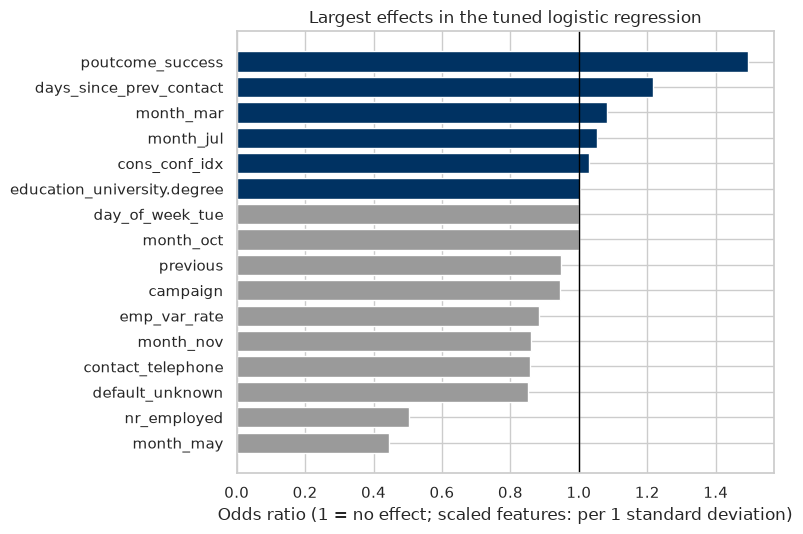

In [27]:
## coefficients of the tuned logistic regression, shown as odds ratios
best_lr = searches["Logistic Regression"].best_estimator_
feature_names = [n.split("__", 1)[1] for n in best_lr.named_steps["prep"].get_feature_names_out()]
coefs = pd.Series(best_lr.named_steps["model"].coef_[0], index=feature_names)
odds_ratios = np.exp(coefs)

print(f"{(coefs != 0).sum()} of {len(coefs)} coefficients are non-zero")
top = pd.concat([coefs.sort_values().head(8), coefs.sort_values().tail(8)])

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, np.exp(top), color=[BLUE if v > 0 else GREY for v in top])
ax.axvline(1, color="black", linewidth=1)
ax.set_xlabel("Odds ratio (1 = no effect; scaled features: per 1 standard deviation)")
ax.set_title("Largest effects in the tuned logistic regression")
plt.tight_layout(); save_fig("logistic_odds_ratios"); plt.show()

**How to read this.** An odds ratio above 1 means the feature raises the odds of subscription, and below 1 lowers them. For numeric features (scaled) it is the effect of a **one standard deviation** increase. For one-hot categories it compares with the reference category (the first alphabetically, e.g. April for `month`, cellular for `contact`).

**What the model learned.** The strong L1 penalty selected by the grid search (`C = 0.01`) kept only **17 of 53** coefficients:

- **Economy.** `nr_employed` has the biggest effect among the numeric features (odds ratio about 0.50 per standard deviation): fewer employed (lower numbers) goes with more subscriptions. `emp_var_rate` also lowers the odds slightly (0.88).
- **Timing.** May is associated with much lower odds than April (about 0.44), and November slightly lower.
- **History.** A previous campaign success raises the odds (about 1.50 versus a previous failure), and more days since the previous contact raises them a little (1.22 per standard deviation).
- **Contact channel and disclosure.** Landline contacts (0.86) and an `unknown` credit-default status (0.85) lower the odds.
- **Client demographics barely appear.** Job, education and age are mostly shrunk to zero.

**Cautions.** The strong penalty shrinks all coefficients, so the odds ratios *understate* the true effects, and the correlated economic indicators make it impossible to attribute an effect to a single one of them. These are associations, not causes.

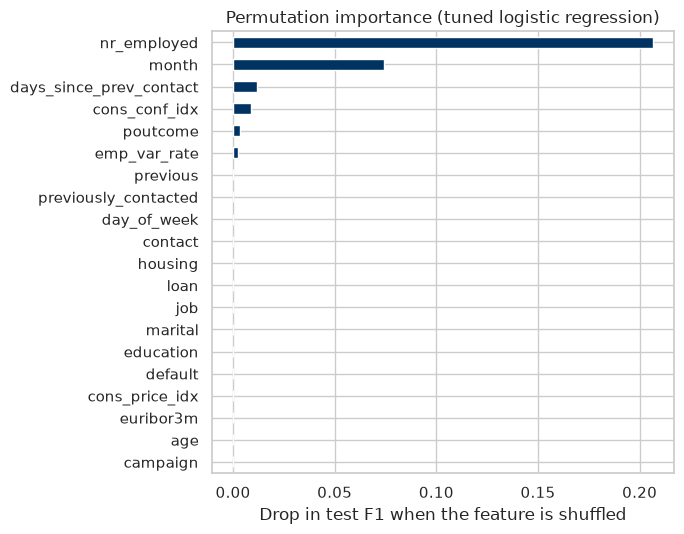

In [28]:
## permutation importance: how much does the F1 score drop when one raw feature is shuffled?
sample_idx = X_test.sample(10_000, random_state=RANDOM_STATE).index
perm = permutation_importance(searches["Logistic Regression"], X_test.loc[sample_idx], y_test.loc[sample_idx],
                              scoring="f1", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
usable = FEATURE_SETS["extended"][0] + FEATURE_SETS["extended"][1] + FEATURE_SETS["extended"][2]
importance = (pd.Series(perm.importances_mean, index=X_test.columns)[usable]
              .sort_values(ascending=True))

fig, ax = plt.subplots(figsize=(7, 5.5))
importance.plot.barh(color=BLUE, ax=ax)
ax.set_xlabel("Drop in test F1 when the feature is shuffled")
ax.set_title("Permutation importance (tuned logistic regression)")
plt.tight_layout(); plt.show()

Permutation importance confirms the picture. Shuffling **`nr_employed`** (the economic indicator) costs the model about **0.21** F1 points, **`month`** about 0.07, and `days_since_prev_contact`, `cons_conf_idx` and `poutcome` only about 0.01 or less. Everything else (age, job, education, marital status, loan, housing) costs essentially nothing. **The model leans almost entirely on when the call happened and on the state of the economy**, and very little on who the client is.

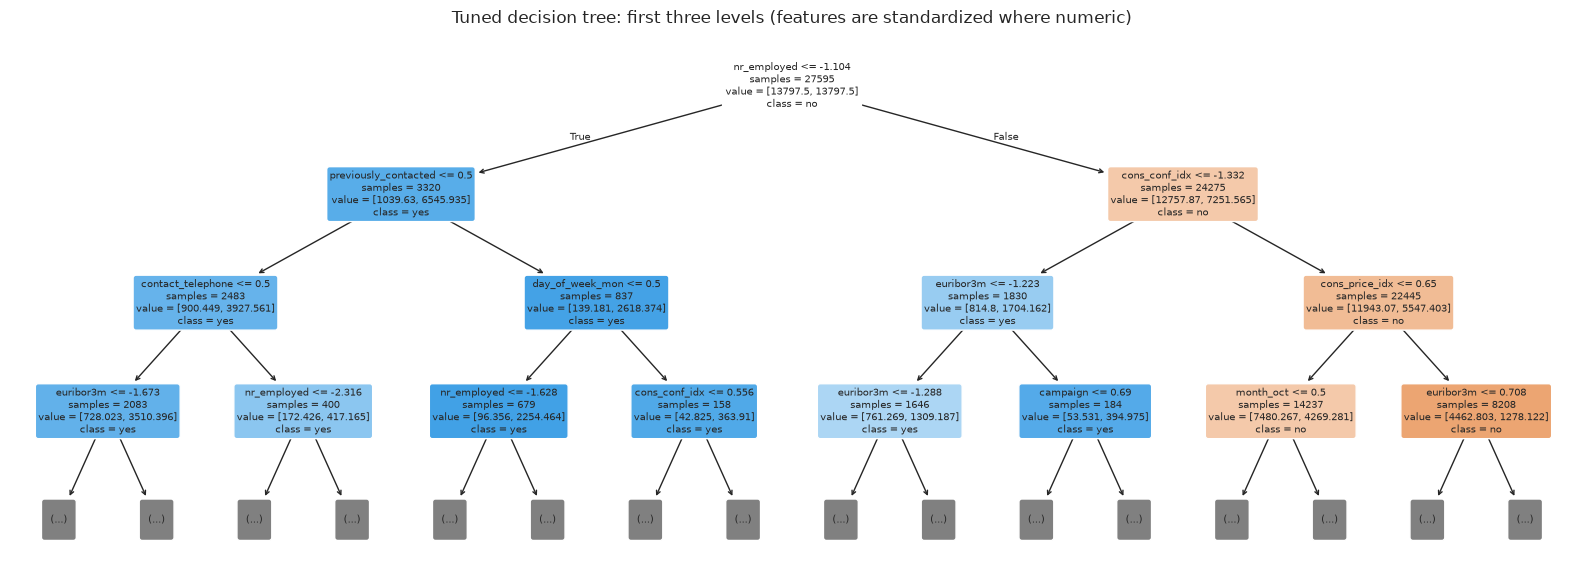

In [29]:
## the top of the tuned decision tree (first three levels), which can be read directly
best_tree = searches["Decision Tree"].best_estimator_
tree_names = [n.split("__", 1)[1] for n in best_tree.named_steps["prep"].get_feature_names_out()]

fig, ax = plt.subplots(figsize=(16, 6))
plot_tree(best_tree.named_steps["model"], feature_names=tree_names, class_names=["no", "yes"],
          max_depth=3, filled=True, rounded=True, fontsize=7, impurity=False, ax=ax)
ax.set_title("Tuned decision tree: first three levels (features are standardized where numeric)")
plt.tight_layout(); plt.show()

The tuned tree tells the same story. Its **very first split is on `nr_employed`**, the economic indicator (standardized threshold of -1.10, roughly 5,088 thousand employees), and economic indicators fill most of the top three levels. In the low-employment branch, the next splits are whether the client was **contacted in a previous campaign** and the **contact type**. A tree is easy to explain, but this one mainly says "look at the economy first".

### 11.5 ROC and precision-recall curves

Accuracy, precision, recall and F1 all depend on where the decision threshold is set. The two curves below show performance at **every** threshold, which is the fair way to compare models that will be used to rank a call list.

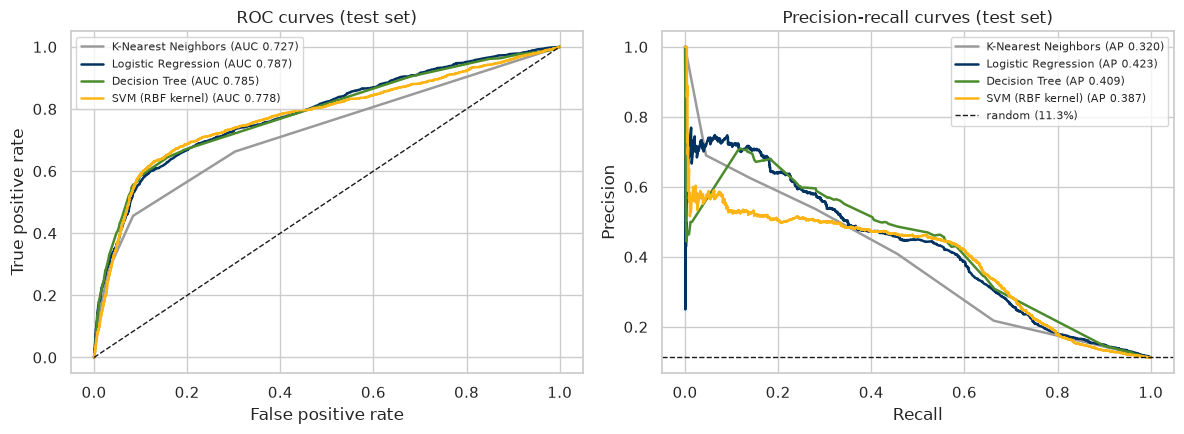

In [30]:
## collect a continuous score from each tuned model
tuned_scores = {}
for name, search in searches.items():
    est = search.best_estimator_
    tuned_scores[name] = (est.predict_proba(X_test)[:, 1] if hasattr(est, "predict_proba")
                          else est.decision_function(X_test))

palette = {"K-Nearest Neighbors": GREY, "Logistic Regression": BLUE,
           "Decision Tree": "#4C8B2B", "SVM (RBF kernel)": GOLD}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, score in tuned_scores.items():
    fpr, tpr, _ = roc_curve(y_test, score)
    axes[0].plot(fpr, tpr, color=palette[name], linewidth=1.8,
                 label=f"{name} (AUC {roc_auc_score(y_test, score):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, score)
    axes[1].plot(rec, prec, color=palette[name], linewidth=1.8,
                 label=f"{name} (AP {average_precision_score(y_test, score):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (test set)")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", linewidth=1, label=f"random ({y_test.mean():.1%})")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curves (test set)")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout(); save_fig("roc_pr_curves"); plt.show()

- **Ranking quality is nearly identical for the three tuned parametric models**: ROC AUC of 0.787 (logistic regression), 0.785 (tree) and 0.778 (SVM), with average precision of 0.423, 0.409 and 0.388. KNN is clearly lower (0.727 and 0.320).
- **All models are far above random** in the precision-recall panel (dashed line at the 11.3% base rate), so there is real signal. But precision falls quickly as recall rises: finding most subscribers means calling many clients who will say no.
- Because ranking quality is tied, the choice between the three comes down to practical factors, which is why I carry **logistic regression** forward.

### 11.6 Choosing the decision threshold

Every metric so far used the default cutoff of 0.5. With about 11% subscribers there is no reason to expect 0.5 to be best. I pick thresholds using **out-of-fold predictions on the training set** (so the test set is not used to choose them) and then apply each threshold **once** to the test set.

Two criteria are compared:

1. **Maximum F1.**
2. **Minimum expected cost**, using an **illustrative** cost assumption: a wasted call costs **1 unit** and a missed subscriber costs **5 units** (a subscription is worth roughly five calls). *These numbers are placeholders; the bank should substitute its real call cost and deposit value.*

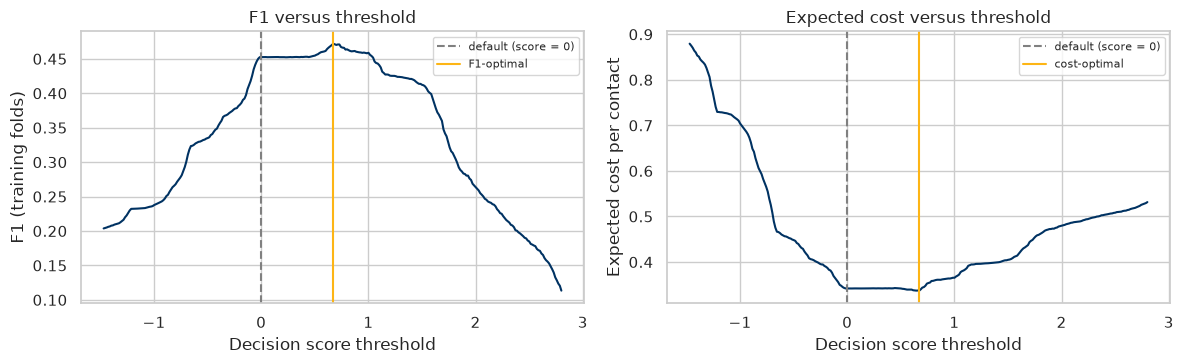

In [31]:
## out-of-fold scores for the tuned logistic regression on the training set
oof_score = cross_val_predict(best_lr, X_train, y_train, cv=cv, method="decision_function")
thresholds = np.linspace(np.percentile(oof_score, 1), np.percentile(oof_score, 99), 300)

COST_FALSE_POSITIVE, COST_FALSE_NEGATIVE = 1.0, 5.0
f1_values, cost_values = [], []
for t in thresholds:
    pred = (oof_score >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    f1_values.append(f1_score(y_train, pred))
    cost_values.append((COST_FALSE_POSITIVE * fp + COST_FALSE_NEGATIVE * fn) / len(y_train))

f1_threshold = thresholds[int(np.argmax(f1_values))]
cost_threshold = thresholds[int(np.argmin(cost_values))]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(thresholds, f1_values, color=BLUE)
axes[0].axvline(0, color="gray", linestyle="--", label="default (score = 0)")
axes[0].axvline(f1_threshold, color=GOLD, label="F1-optimal")
axes[0].set(xlabel="Decision score threshold", ylabel="F1 (training folds)", title="F1 versus threshold")
axes[1].plot(thresholds, cost_values, color=BLUE)
axes[1].axvline(0, color="gray", linestyle="--", label="default (score = 0)")
axes[1].axvline(cost_threshold, color=GOLD, label="cost-optimal")
axes[1].set(xlabel="Decision score threshold", ylabel="Expected cost per contact", title="Expected cost versus threshold")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [32]:
## apply the three thresholds to the test set, once
test_score = best_lr.decision_function(X_test)
rows = []
for label, t in [("default (score = 0)", 0.0), ("F1-optimal", f1_threshold), ("cost-optimal", cost_threshold)]:
    pred = (test_score >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"Threshold": label, "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred), "Calls made": int(pred.sum()),
                 "Subscribers found": int(tp),
                 "Expected cost / contact": (COST_FALSE_POSITIVE * fp + COST_FALSE_NEGATIVE * fn) / len(y_test)})
threshold_table = pd.DataFrame(rows).set_index("Threshold").round(3)
threshold_table

,Accuracy,Precision,Recall,F1,Calls made,Subscribers found,Expected cost / contact
Threshold,,,,,,,
default (score = 0),0.832,0.357,0.610,0.450,2616,934,0.343
F1-optimal,0.857,0.406,0.583,0.479,2196,892,0.331
cost-optimal,0.857,0.406,0.583,0.479,2196,892,0.331


**Observations**

- **The default cutoff (score 0) is not the best.** Raising it to the F1-optimal value (about 0.67 on the score scale) improves F1 from 0.450 to **0.479** and accuracy from 83.2% to 85.7%. It makes **2,196 calls instead of 2,616 (420 fewer, 16% fewer)** and finds 892 subscribers instead of 934 (42 fewer, 4.5% fewer). Most of the removed calls were wasted.
- **At the illustrative 5:1 cost ratio, the F1-optimal and cost-optimal thresholds are the same.** This happens because the clients just below the cutoff convert at a hit rate under 1 in 6 (the break-even point at a 5:1 ratio), so calling them costs more than it earns. It is a result, not a bug.
- **The sensitivity table shows why the cost ratio matters.** If a missed subscriber is no worse than a wasted call (1x), the bank should call only about 400 clients with 68% precision and find 18% of subscribers. If a missed sale costs 10x, it should call 3,300 clients (31% precision) and find 66%. If it costs 20x, it should call over 10,000 clients (14% precision) to find 93%. **The right cutoff is a business decision based on the bank's real costs**, and these numbers show the range.

**How sensitive is the plan to the cost assumption?** The 1:5 ratio is only a guess, so the table below repeats the threshold choice for several ratios of (cost of a missed subscriber) to (cost of a wasted call).

In [33]:
## re-pick the cost-optimal threshold for several cost ratios (chosen on training folds, applied to the test set)
rows = []
for ratio in [1, 2, 5, 10, 20]:
    costs_r = []
    for t in thresholds:
        pred = (oof_score >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
        costs_r.append((fp + ratio * fn) / len(y_train))
    t_best = thresholds[int(np.argmin(costs_r))]
    pred = (test_score >= t_best).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"Missed sale costs x wasted calls": f"{ratio}x", "Calls made": int(pred.sum()),
                 "Subscribers found": int(tp), "Share of all subscribers found": tp / (tp + fn),
                 "Hit rate (precision)": tp / pred.sum()})
cost_sensitivity = pd.DataFrame(rows).set_index("Missed sale costs x wasted calls").round(3)
cost_sensitivity

,Calls made,Subscribers found,Share of all subscribers found,Hit rate (precision)
Missed sale costs x wasted calls,,,,
1x,397,271,0.177,0.683
2x,1329,629,0.411,0.473
5x,2196,892,0.583,0.406
10x,3300,1012,0.661,0.307
20x,10349,1427,0.932,0.138


### 11.7 Lift: what if the bank only calls the best-ranked clients?

In [34]:
## rank test clients by score and see how many subscribers fall in the top k percent
order = np.argsort(-test_score)
y_ranked = y_test.to_numpy()[order]
total_yes = y_ranked.sum()

rows = []
for pct in [0.05, 0.10, 0.20, 0.30, 0.50]:
    k = int(len(y_ranked) * pct)
    captured = y_ranked[:k].sum()
    rows.append({"Clients called (top %)": f"{pct:.0%}", "Subscribers captured": int(captured),
                 "Share of all subscribers": captured / total_yes,
                 "Hit rate": captured / k, "Lift vs random": (captured / k) / y_test.mean()})
lift_table = pd.DataFrame(rows).set_index("Clients called (top %)").round(3)
lift_table

,Subscribers captured,Share of all subscribers,Hit rate,Lift vs random
Clients called (top %),,,,
5%,398,0.260,0.586,5.204
10%,638,0.417,0.469,4.168
20%,946,0.618,0.348,3.090
30%,1072,0.700,0.263,2.335
50%,1226,0.801,0.180,1.602


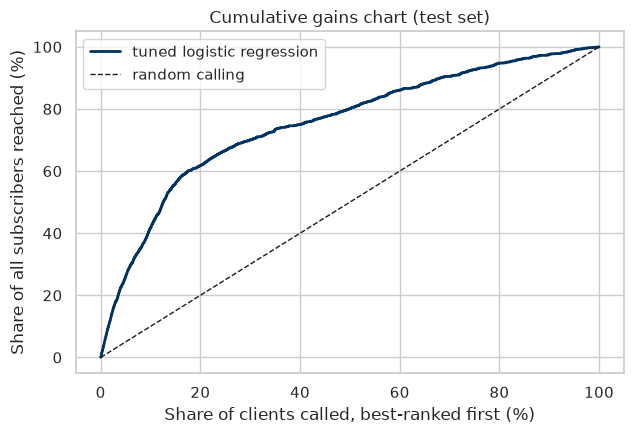

In [35]:
## cumulative gains chart
share_called = np.arange(1, len(y_ranked) + 1) / len(y_ranked)
share_found = np.cumsum(y_ranked) / total_yes

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(share_called * 100, share_found * 100, color=BLUE, linewidth=2, label="tuned logistic regression")
ax.plot([0, 100], [0, 100], "k--", linewidth=1, label="random calling")
ax.set(xlabel="Share of clients called, best-ranked first (%)",
       ylabel="Share of all subscribers reached (%)", title="Cumulative gains chart (test set)")
ax.legend()
plt.tight_layout(); save_fig("gains_chart"); plt.show()

**Calling the best-ranked clients first captures far more than calling at random.**

- Calling the **top 10%** of ranked clients reaches **41.7%** of all subscribers (a hit rate of 46.9%, which is **4.2 times better than random**).
- The **top 20%** reaches **61.8%** of subscribers (3.1 times better than random).
- The **top 50%** reaches 80.1% of subscribers, so the bank could skip half of the call list and lose only a fifth of the subscribers.

The gains chart shows the curve bowing well above the dashed random line. This is the most practical output for a marketing team, because it answers "given the calls we can afford, how many subscribers do we reach?" These results are on a random test split, and section 11.8 shows why they should be treated with care.

### 11.8 Robustness: does it still work on later data?

The rows are in date order (May 2008 to November 2010), and the economic indicators changed a lot over that period. A random split lets the model see every period during training. A fairer test of real use is to **train on the earliest 70% of contacts and test on the latest 30%**. I run it for the extended feature set and for the version **without the economic indicators**, to see which one holds up.

In [36]:
## time-ordered split: earliest 70% for training, latest 30% for testing
cut = int(len(X) * 0.70)
X_early, X_late, y_early, y_late = X.iloc[:cut], X.iloc[cut:], y.iloc[:cut], y.iloc[cut:]
print(f"subscription rate: first 70% = {y_early.mean():.1%}, last 30% = {y_late.mean():.1%}")

## same tuned logistic regression settings, with and without the economic indicators
best_params = {k.replace("model__", ""): v for k, v in searches["Logistic Regression"].best_params_.items()}
def lr_with_best_params(feature_set):
    return make_pipeline(LogisticRegression(max_iter=5000, solver="liblinear", **best_params), feature_set)

rows = []
for feature_set in ["extended", "no economic indicators"]:
    for split, (X_a, y_a, X_b, y_b) in {"random split": (X_train, y_train, X_test, y_test),
                                        "time split (train early, test late)": (X_early, y_early, X_late, y_late)}.items():
        model = lr_with_best_params(feature_set).fit(X_a, y_a)
        rows.append({"Features": feature_set, "Evaluation": split, **score_model(model, X_b, y_b)})
time_check = pd.DataFrame(rows).set_index(["Features", "Evaluation"]).round(3)
time_check

subscription rate: first 70% = 5.6%, last 30% = 24.6%


Accuracy  Precision  Recall     F1  ROC AUC  PR AUC
Features               Evaluation                                                                              
extended               random split                            0.832      0.357   0.610  0.450    0.787   0.423
                       time split (train early, test late)     0.250      0.230   0.876  0.364    0.403   0.241
no economic indicators random split                            0.770      0.266   0.591  0.367    0.759   0.381
                       time split (train early, test late)     0.669      0.403   0.721  0.517    0.750   0.478

**This is the most important robustness result in the notebook.**

| | Random split | Time split (train early, test late) |
|---|---|---|
| **With economic indicators** (extended) | ROC AUC 0.787, F1 0.450 | **ROC AUC 0.403, F1 0.364** |
| **Without economic indicators** | ROC AUC 0.759, F1 0.367 | **ROC AUC 0.750, F1 0.517** |

- **The model with the economic indicators fails on later data.** Its ROC AUC falls to **0.40**, worse than a coin flip, meaning its ranking is *inverted* on the later contacts. Accuracy drops to 25% because it flags nearly everyone (recall 0.88, precision 0.23).
- **Without the economic indicators the model holds up** (ROC AUC 0.750, about the same as on the random split).
- **Why this probably happens.** The economy was very different in the two periods. The first 70% of contacts mostly had interest rates near 4.9% and a 5.6% subscription rate, while the last 30% mostly had rates near 1% and a **24.6%** subscription rate. The economic indicators barely change within a quarter, so on a random split they mostly tell the model *which period* a call was in and what that period's typical rate was. The model can learn that, but it does not transfer to a new period.
- **Implication.** The random-split scores above, especially for models that lean on the economic indicators, are **optimistic** for a real forward-looking use. A model built on client, contact and campaign-history features is the safer choice. (The F1 of the time-split no-economic model is higher partly because the later period has more subscribers, so a higher hit rate is easier to reach.)

---
## Final Model and Evaluation

### Choice of model

I choose the **tuned logistic regression** (L1 penalty, `C = 0.01`, balanced class weights) as the final model. Logistic regression, the decision tree and the SVM are tied within noise on ROC AUC, so I choose on practical grounds:

- it **fits in about 5 seconds**, against about 270 seconds for the SVM grid search,
- it produces **scores that rank clients**, which the threshold, cost and lift analysis all rely on,
- and its **17 surviving coefficients can be explained** to the marketing team.

### Final performance on the test set

With the F1/cost-optimal threshold the model reaches **precision 0.41, recall 0.58 and F1 0.48**, and ROC AUC of 0.79. It makes 2,196 calls and finds 892 of the 1,531 subscribers in the test set. Accuracy is 85.7%, below the 88.7% baseline, which is expected because the baseline never finds a subscriber.

### The caveat that matters

The section 11.8 results show that the version **with the economic indicators** does not hold up on later data. For forward-looking use I therefore recommend the **version without economic indicators** (ROC AUC about 0.75 on both the random and the time split). Both versions are in the notebook so the trade-off is visible.

In [37]:
## classification report for the chosen model at the cost-optimal threshold
final_pred = (test_score >= cost_threshold).astype(int)
print(classification_report(y_test, final_pred, target_names=["no subscription", "subscription"], digits=3))

                 precision    recall  f1-score   support

no subscription      0.944     0.892     0.917     12062
   subscription      0.406     0.583     0.479      1531

       accuracy                          0.857     13593
      macro avg      0.675     0.737     0.698     13593
   weighted avg      0.883     0.857     0.868     13593



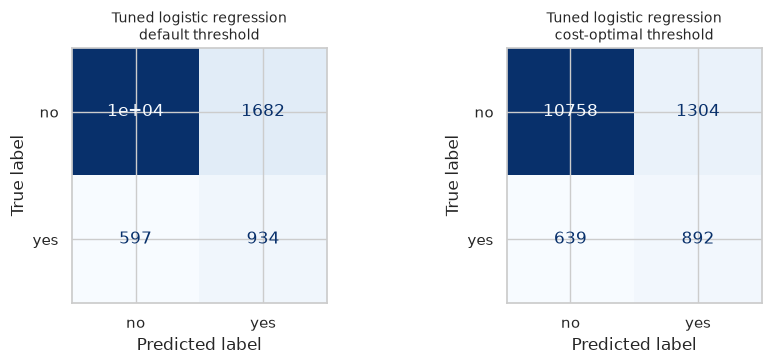

In [38]:
## confusion matrices at the default and cost-optimal thresholds
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (label, t) in zip(axes, [("default threshold", 0.0), ("cost-optimal threshold", cost_threshold)]):
    ConfusionMatrixDisplay.from_predictions(y_test, (test_score >= t).astype(int),
                                            display_labels=["no", "yes"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Tuned logistic regression\n{label}", fontsize=10)
plt.tight_layout(); plt.show()

---
## Findings

*This section is written for the bank's marketing team, without technical language.*

### The short version

- **Who says yes can be predicted, but only partly.** The best model finds about **58% of the people who would subscribe** by calling only about **16% of the clients**. Calling the top-ranked 20% of clients reaches about **62%** of all subscribers, around **three times better than calling at random**.
- **Who the client is matters less than you might expect. When and how you reach them matters more.**
- **Do not rely on call length or on interest-rate numbers to plan calls.** Call length is only known after the call, and interest-rate numbers worked only in the periods the model learned from.

### What we learned about the clients and the calls

1. **Past customers are the best prospects.** Clients who said yes to an earlier campaign subscribed **65%** of the time, against 9% for clients never contacted before. They are only 3% of the call list.
2. **Mobile beats landline.** Cellular contacts subscribed **14.7%** of the time versus **5.2%** for landline contacts.
3. **Students and retirees respond best** (31% and 25%), and the very oldest clients respond most of all (47% for those over 64). Blue-collar workers and people in service jobs respond least (about 7% to 8%).
4. **Timing matters.** The bank made a third of its calls in **May, its weakest month (6.4% success)**, while March, September, October and December had success rates of 44% to 51% on far fewer calls. This does not prove that shifting calls would work, because those months also differ in the economy, but it is worth testing.
5. **Things that do not help predict a "yes"**: whether the client has a home loan or a personal loan, and the day of the week.

### Recommended actions

- **Call past customers first.** Put clients with a successful previous campaign at the top of the list.
- **Use mobile numbers wherever possible.**
- **Rank the call list with the model and stop earlier.** If the team has to cut the list, the model lets it cut the lowest-ranked clients: calling the top **half** of the list reaches about **80%** of subscribers.
- **Set the cutoff from real costs.** The number of calls to make depends on what a call costs and what a subscription is worth. The table in 11.6 shows the range: from about 400 calls (high precision, 18% of subscribers found) to about 10,000 calls (93% found).
- **Test the timing idea with a small controlled trial** (for example, shift part of May's calls to autumn) before changing the whole schedule.
- **Keep the model fresh.** Rebuild it regularly and check it on recent calls. The version built on client and contact information held up over time; the version built on interest-rate numbers did not.
- **Never use call duration to decide whom to call.** It looks very predictive, but it is only known once the call has ended.

### Limits of this analysis

- The data are from 2008 to 2010 in one Portuguese bank, so the patterns may differ today.
- The findings describe **associations, not causes**.
- The model is useful for ranking, but it is far from perfect: even at its best setting, about 6 in 10 of the clients it flags will say no.
- The cost figures used for the cutoff are illustrative and should be replaced with the bank's own.

---
## Next Steps and Recommendations

### Next steps for the modeling work

- **Try ensembles.** Random forests and gradient boosting handle mixed data and interactions without special encoding, and are the natural next step since three single models tied.
- **Time-aware validation.** Use rolling or expanding-window validation instead of a single random split, and report results by period, so the model is judged the way it will be used.
- **Reduce dependence on the economic indicators.** Test using them only as differences or lags, or retrain frequently, and monitor whether the model's score distribution drifts.
- **Check calibration.** The cost analysis assumes scores behave like probabilities. A calibration curve, and Platt or isotonic scaling if needed, should be checked before the cutoff is trusted.
- **Repeated cross-validation.** The top three models differ by less than 0.04 F1 on one split. Repeated stratified cross-validation would show whether their ordering is stable.
- **Richer features.** For example, the number of previous successes, time since the last contact in days, and interactions between contact type and month.
- **Replace the cost assumption** with the bank's real call cost and deposit value, and re-run the threshold analysis.
- **Governance.** Before using age or marital status to target clients, review the fairness and regulatory implications.

### Recommendations

1. Deploy the **logistic regression without the economic indicators** as the first ranking model, with the cutoff set from real costs.
2. **Run an A/B test**: ranked call list versus the current list, measuring subscriptions per call.
3. **Retrain on a schedule** and monitor weekly whether the hit rate among the top-ranked clients stays near the level seen here.